# Follow-up Lab: Decision Trees versus Naïve Bayes

In the previous lab, you built a Naïve Bayes classifier for the same question:

> Can we predict whether a name is labeled male or female?

You also developed the final feature function, gender_features5. In this follow-up, we will **keep the data, the train/dev-test/test split, and the features exactly the same**. The only major change is the classifier: we will replace Naïve Bayes with an NLTK decision tree.

We will then compare the two models:

- What features does each model find informative?
- Which model performs better?
- How do their accuracy, precision, recall, and F1 scores differ?


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
import random
import nltk
nltk.download('names')

[nltk_data] Downloading package names to /root/nltk_data...
[nltk_data]   Unzipping corpora/names.zip.


True

In [ ]:
from nltk.corpus import names

In [ ]:
labeled_names = ([(name, 'male') for name in names.words('male.txt')] + [(name, 'female') for name in names.words('female.txt')])

In [ ]:
random.Random(2026).shuffle(labeled_names)

In [ ]:
train_names = labeled_names[1500:]
devtest_names = labeled_names[500:1500]
test_names = labeled_names[:500]

In [ ]:
def gender_features5(name):
  features = {}
  features["first_letter"] = name[0].lower()
  features["last_letter"] = name[-1].lower()
  features["suffix"]= name[-2:].lower()
  features["length"] = len(name)

  for letter in 'abcdefghijklmnopqrstuvwxyz':
    features["count({})".format(letter)] = name.lower().count(letter)
  return features

In [ ]:
train_set = [(gender_features5(n), gender) for (n, gender) in train_names]
devtest_set = [(gender_features5(n), gender) for (n, gender) in devtest_names]
test_set = [(gender_features5(n), gender) for (n, gender) in test_names]

## 1. Recreate the previous Naïve Bayes model

The previous lab already trained a Naïve Bayes model with these feature dictionaries. We retrain it here under a clearer name so that we can compare it directly with the new decision-tree model.

There is no new feature engineering in this section.


In [ ]:
from nltk.classify import NaiveBayesClassifier

nb_classifier = NaiveBayesClassifier.train(train_set)

print('Naïve Bayes development accuracy:',
      nltk.classify.accuracy(nb_classifier, devtest_set))


Naïve Bayes development accuracy: 0.772


## 2. Replace the classifier with an NLTK decision tree

Unlike a scikit-learn decision tree, NLTK's decision tree accepts the same feature dictionaries that Naïve Bayes uses. This means we do not need a feature-to-column conversion step.

The setting binary=True asks the tree to consider questions such as:

    Is suffix equal to yn?

This makes the tree's decisions easy to compare with the feature-value evidence reported by Naïve Bayes.


In [ ]:
from nltk.classify import DecisionTreeClassifier

tree_classifier = DecisionTreeClassifier.train(train_set, binary=True, depth_cutoff=8)

print('Decision-tree development accuracy:',
      nltk.classify.accuracy(tree_classifier, devtest_set))


Decision-tree development accuracy: 0.752


## 3. Inspect the decision tree

The tree's upper levels contain its earliest and usually most influential decisions. We display the first three levels using NLTK's own tree-formatting function.


In [ ]:
print(tree_classifier.pseudocode(depth=2))


if last_letter == 'd': 
  if count(a) == 3: return 'female'
  if count(a) != 3: return 'male'
if last_letter != 'd': 
  if last_letter == 'r': return 'male'
  if last_letter != 'r': return 'male'



## 4. Compare the most informative features

Naïve Bayes and a decision tree do not define feature importance in exactly the same way.

- Naïve Bayes reports feature-value pairs with large likelihood ratios.
- The decision tree places highly useful split features near the top of the tree.


In [ ]:
nb_classifier.show_most_informative_features(5)

Most Informative Features
                  suffix = 'na'           female : male   =    144.5 : 1.0
                  suffix = 'ia'           female : male   =     48.1 : 1.0
                  suffix = 'ld'             male : female =     36.1 : 1.0
             last_letter = 'k'              male : female =     35.0 : 1.0
             last_letter = 'a'            female : male   =     34.7 : 1.0


### Interpretation

Compare the Naïve Bayes table with the decision-tree display.

1. Which feature-value pairs are informative for Naïve Bayes?
2. What is the decision tree's first split?
3. Do the two models focus on the same evidence? Why might their rankings differ even though they use exactly the same feature dictionaries?


# Your Turn

Make a non-binary tree and inspect the first feature of the tree's split. What is the most useful feature this time?

In [ ]:
tree_classifier1 = DecisionTreeClassifier.train(train_set, binary=True, depth_cutoff=8)

print('Decision-tree development accuracy:',
      nltk.classify.accuracy(tree_classifier1, devtest_set))

Decision-tree development accuracy: 0.752


## 5. Generate predictions on the same test set

Both models now classify exactly the same test feature dictionaries.


In [ ]:
# Gold labels
gold = [label for features, label in test_set]

# Feature dictionaries for the test set
test_features = [features for features, label in test_set]

# Predictions from NLTK models
nb_predictions = nb_classifier.classify_many(test_features)
tree_predictions = tree_classifier.classify_many(test_features)

print('First 5 gold labels: ', gold[:5])
print('First 5 Naïve Bayes predictions: ', nb_predictions[:5])
print('First 5 decision-tree predictions:', tree_predictions[:5])


First 5 gold labels:  ['male', 'male', 'male', 'female', 'female']
First 5 Naïve Bayes predictions:  ['male', 'female', 'male', 'female', 'female']
First 5 decision-tree predictions: ['male', 'female', 'male', 'female', 'female']


For precision, recall, and F1, we use the package of sklearn. We calculate the score for male and female separately and then take the macro average.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

In [ ]:
precision_score(gold, nb_predictions, average='macro')

0.8020148060213352

In [ ]:
precision_score(gold, tree_predictions, average='macro')

0.777355623100304

In [ ]:
precision_score(gold, nb_predictions, average='micro')

0.812

In [ ]:
precision_score(gold, tree_predictions, average='micro')

0.738

In [ ]:
recall_score(gold, nb_predictions, average='macro')

0.8079865489701555

In [ ]:
def evaluate_model(gold, predictions):
    return {
        'accuracy': accuracy_score(gold, predictions),
        'precision': precision_score(
            gold, predictions, average='macro'
        ),
        'recall': recall_score(
            gold, predictions, average='macro'
        ),
        'f1': f1_score(
            gold, predictions, average='macro'
        ),
    }

metrics_df = pd.DataFrame([
    {
        'model': 'Naïve Bayes',
        **evaluate_model(gold, nb_predictions),
    },
    {
        'model': 'Decision Tree',
        **evaluate_model(gold, tree_predictions),
    },
])

metrics_df.round(3)

,model,accuracy,precision,recall,f1
0,Naïve Bayes,0.812,0.802,0.808,0.804
1,Decision Tree,0.738,0.777,0.678,0.681


## 7. How does tree depth affect performance?

This is still the same decision-tree algorithm and the same feature dictionaries. We only change the depth cutoff.

Use NLTK's error method to compare training, development, and test accuracy. A very shallow tree may underfit; a very deep tree may overfit.


In [ ]:
depth_results = []

for depth in [1, 3, 6, 9, 12, 18]:
    model = DecisionTreeClassifier.train(
        train_set,
        binary=True,
        depth_cutoff=depth,
    )

    training_accuracy = nltk.classify.accuracy(model, train_set)
    development_accuracy = nltk.classify.accuracy(model, devtest_set)
    test_accuracy = nltk.classify.accuracy(model, test_set)

    depth_results.append({
        'depth_cutoff': depth,
        'training_accuracy': training_accuracy,
        'development_accuracy': development_accuracy,
        'test_accuracy': test_accuracy,
    })

depth_df = pd.DataFrame(depth_results)
depth_df.round(3)

,depth_cutoff,training_accuracy,development_accuracy,test_accuracy
0,1,0.655,0.652,0.634
1,3,0.692,0.680,0.670
2,6,0.744,0.719,0.702
3,9,0.779,0.756,0.748
4,12,0.796,0.764,0.768
5,18,0.812,0.776,0.780


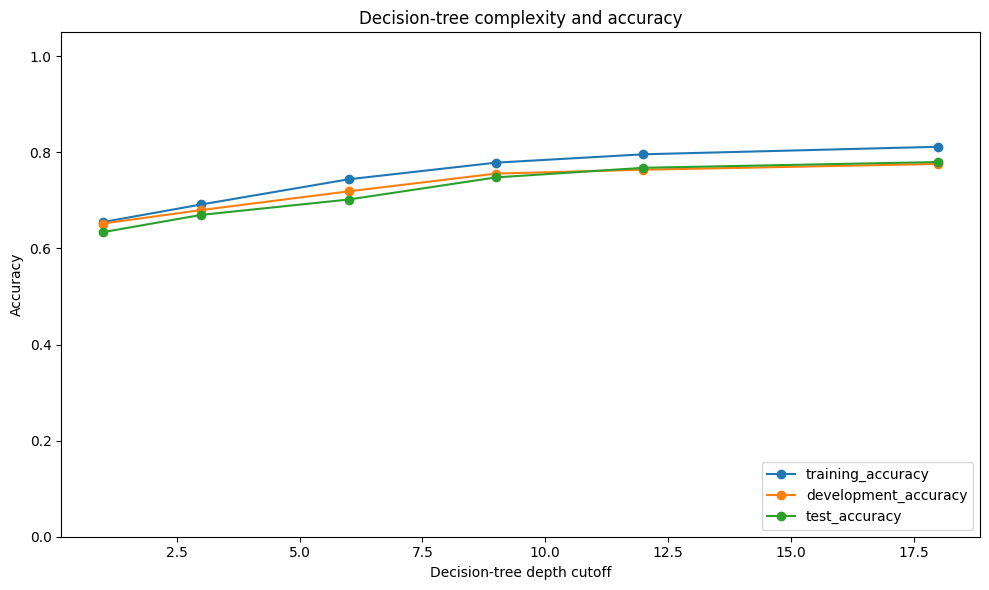

In [ ]:
depth_plot = depth_df.set_index('depth_cutoff')
depth_plot.plot(marker='o', figsize=(10, 6))
plt.ylim(0, 1.05)
plt.ylabel('Accuracy')
plt.xlabel('Decision-tree depth cutoff')
plt.title('Decision-tree complexity and accuracy')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


## Final reflection

1. Which model performed better on the unseen test set?
2. Which feature-value pairs were most informative for Naïve Bayes?
3. What feature did the decision tree use for its first split?
4. Did the two models focus on the same evidence?
5. What do the precision, recall, F1, and confusion matrices reveal that accuracy alone does not?
6. What pattern do you see as the decision-tree depth increases?
